In [1]:
import random

import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

from scipy.stats import weightedtau

import sys
sys.path.append("./../") 

from scripts.utils import load_array

In [2]:
# Set random seeds for reproducability
np.random.seed(12)
random.seed(12)

In [3]:
colors = ["#A338C4", '#248EF1', "#29BA10", '#F68D0E', '#F12476']

In [4]:
datasets = ['opportunity_uni', 'fordA', 'turbofan']
n_reps = 5
noise_sigma = 1

In [5]:
def compare(shap_path1, shap_path2, base_path1, base_path2, task):
    """
    Compare sets of SHAP values
    shap_path1: path to first set of SHAP values for n samples
    shap_path2: path to second set of SHAP values for the same n samples
    base_path1: parth to corresponding first set of base values
    base_path2: parth to corresponding second set of base values
    task: task of predictive model, classification or regression
    returns: weighted taus and RMSE for all samples in the given sets of SHAP values
    """
    # Load SHAP values
    shap_values1 = load_array(shap_path1)
    shap_values1 = np.squeeze(np.array(shap_values1))

    shap_values2 = load_array(shap_path2)
    shap_values2 = np.squeeze(np.array(shap_values2))

    # Normalize SHAP values
    shap_values1_norm = (shap_values1 - np.mean(shap_values1)) / np.std(shap_values1)
    shap_values2_norm = (shap_values2 - np.mean(shap_values2)) / np.std(shap_values2)

    # Load base values to determine model prediction
    base_values1 = np.squeeze(load_array(base_path1))

    if task == 'classification':
        # Determine model prediction to select correct set of SHAP values
        y_logits = np.sum(shap_values1, axis=1) + base_values1
        y_pred = np.argmax(y_logits, axis=1)

        # Determine weighted taus of SHAP value pair
        weightedtaus = [weightedtau(np.abs(s1[:, y]), np.abs(s2[:, y])).statistic \
            for s1, s2, y in zip(shap_values1_norm, shap_values2_norm, y_pred)]
    else:
        # Determine model prediction to select correct set of SHAP values
        y_pred = np.sum(shap_values1, axis=1) + base_values1

        # Determine weighted taus of SHAP value pair
        weightedtaus = [weightedtau(np.abs(s1), np.abs(s2)).statistic \
            for s1, s2 in zip(shap_values1_norm, shap_values2_norm)]

    # Determine RMSE of SHAP value sets
    rmse = [np.sqrt(np.mean((s1 - s2) ** 2)) for s1, s2 in zip(shap_values1_norm, shap_values2_norm)]
    return weightedtaus, rmse

In [6]:
def compare_randomized(shap_path1,  base_path1, task):
    """
    Compare random sets of SHAP values as baseline
    shap_path1: path to set of SHAP values for n samples
    base_path1: parth to set of base values
    task: task of predictive model, classification or regression
    returns: weighted taus and RMSE for all samples in the given sets of SHAP values
    """
    # Load SHAP values
    shap_values1 = load_array(shap_path1)
    shap_values1 = np.squeeze(np.array(shap_values1))

    shap_values2 = np.copy(shap_values1)
    np.random.shuffle(shap_values2)

    # Normalize SHAP values
    shap_values1_norm = (shap_values1 - np.mean(shap_values1)) / np.std(shap_values1)
    shap_values2_norm = (shap_values2 - np.mean(shap_values2)) / np.std(shap_values2)

    # Load base values to determine model prediction
    base_values1 = np.squeeze(load_array(base_path1))

    if task == 'classification':
        # Determine model prediction to select correct set of SHAP values
        y_logits = np.sum(shap_values1, axis=1) + base_values1
        y_pred = np.argmax(y_logits, axis=1)

        # Determine weighted taus of SHAP value pair
        weightedtaus = [weightedtau(np.abs(s1[:, y]), np.abs(s2[:, y])).statistic \
            for s1, s2, y in zip(shap_values1_norm, shap_values2_norm, y_pred)]
    else:
        # Determine model prediction to select correct set of SHAP values
        y_pred = np.sum(shap_values1, axis=1) + base_values1

        # Determine weighted taus of SHAP value pair
        weightedtaus = [weightedtau(np.abs(s1), np.abs(s2)).statistic \
            for s1, s2 in zip(shap_values1_norm, shap_values2_norm)]

    # Determine RMSE of SHAP value sets
    rmse = [np.sqrt(np.mean((s1 - s2) ** 2)) for s1, s2 in zip(shap_values1_norm, shap_values2_norm)]
    return weightedtaus, rmse

In [7]:
# Used for storing results for all datasets and both metrics
result_dict = {d: {m: {}
               for m in ['taus', 'rmse']} for d in datasets}

In [8]:
for dataset in datasets:
    if dataset == 'opportunity_uni':
        og_value = 27
        vals = [17, 22, 25, 29, 32, 37, 'shuffle']
        task = 'classification'
        decomposition_def = 'trend+bias+scalex(low_freq+varxhigh_freq)'
    elif dataset == 'fordA':
        og_value = 50
        vals = [40, 45, 48, 52, 55, 60, 'shuffle']
        task = 'classification'
        decomposition_def = 'scalex(low_freq+varxhigh_freq)'
    elif dataset == 'turbofan':
        og_value = 30
        vals = [20, 25, 28, 32, 35, 40, 'shuffle']
        task = 'regression'
        decomposition_def = 'trend+bias+scalex(low_freq+varxhigh_freq)'

    result_dict[dataset]['taus'] = {int(v - og_value) if type(v) is not str else v: [[]] * n_reps for v in vals} 
    result_dict[dataset]['rmse'] = {int(v - og_value) if type(v) is not str else v: [[]] * n_reps for v in vals} 
    
    # Determine paths
    shap_path_og = './../data/cshap/' + dataset + '/uni_channel/' + decomposition_def
    shap_path_sa = './../data/results/sensitivity_analysis/' + dataset + '/uni_channel/' + decomposition_def
    model_path = './../models/' + dataset + '/uni_channel'

    for i in range(n_reps):
        for v in vals[:-1]:          # Iterate through the 5 pairs
        
            # Load paths based on selected models
            shap_path1 = shap_path_og + '/shap_values' + str(i) + '.pkl'
            shap_path2 = shap_path_sa + '/v_w_size_' + str(v) + '_noise_' + str(noise_sigma) + '_shap_values_' + str(i) + '.pkl'

            base_path1 = shap_path_og + '/base_values' + str(i) + '.pkl'
            base_path2 = shap_path_sa + '/v_w_size_' + str(v) + '_noise_' + str(noise_sigma) + '_base_values_' + str(i) + '.pkl'
            
            # Do pairwise sample comparisons
            weightedtaus, rmse = compare(shap_path1, shap_path2, base_path1, base_path2, task)

            # Store results
            result_dict[dataset]['taus'][int(v - og_value)][i] = weightedtaus
            result_dict[dataset]['rmse'][int(v - og_value)][i] = rmse

        # Do pairwise sample comparisons
        weightedtaus, rmse = compare_randomized(shap_path1, base_path1, task)

        # Store results
        result_dict[dataset]['taus']['shuffle'][i] = weightedtaus
        result_dict[dataset]['rmse']['shuffle'][i] = rmse   


In [9]:
# Calculate means over shap pairs
mean_dict = {dataset: {t: {d: np.mean(sub_d, axis=0) 
                        for d, sub_d in sub_t.items()} 
                        for t, sub_t in sub.items()} for dataset, sub in result_dict.items()}

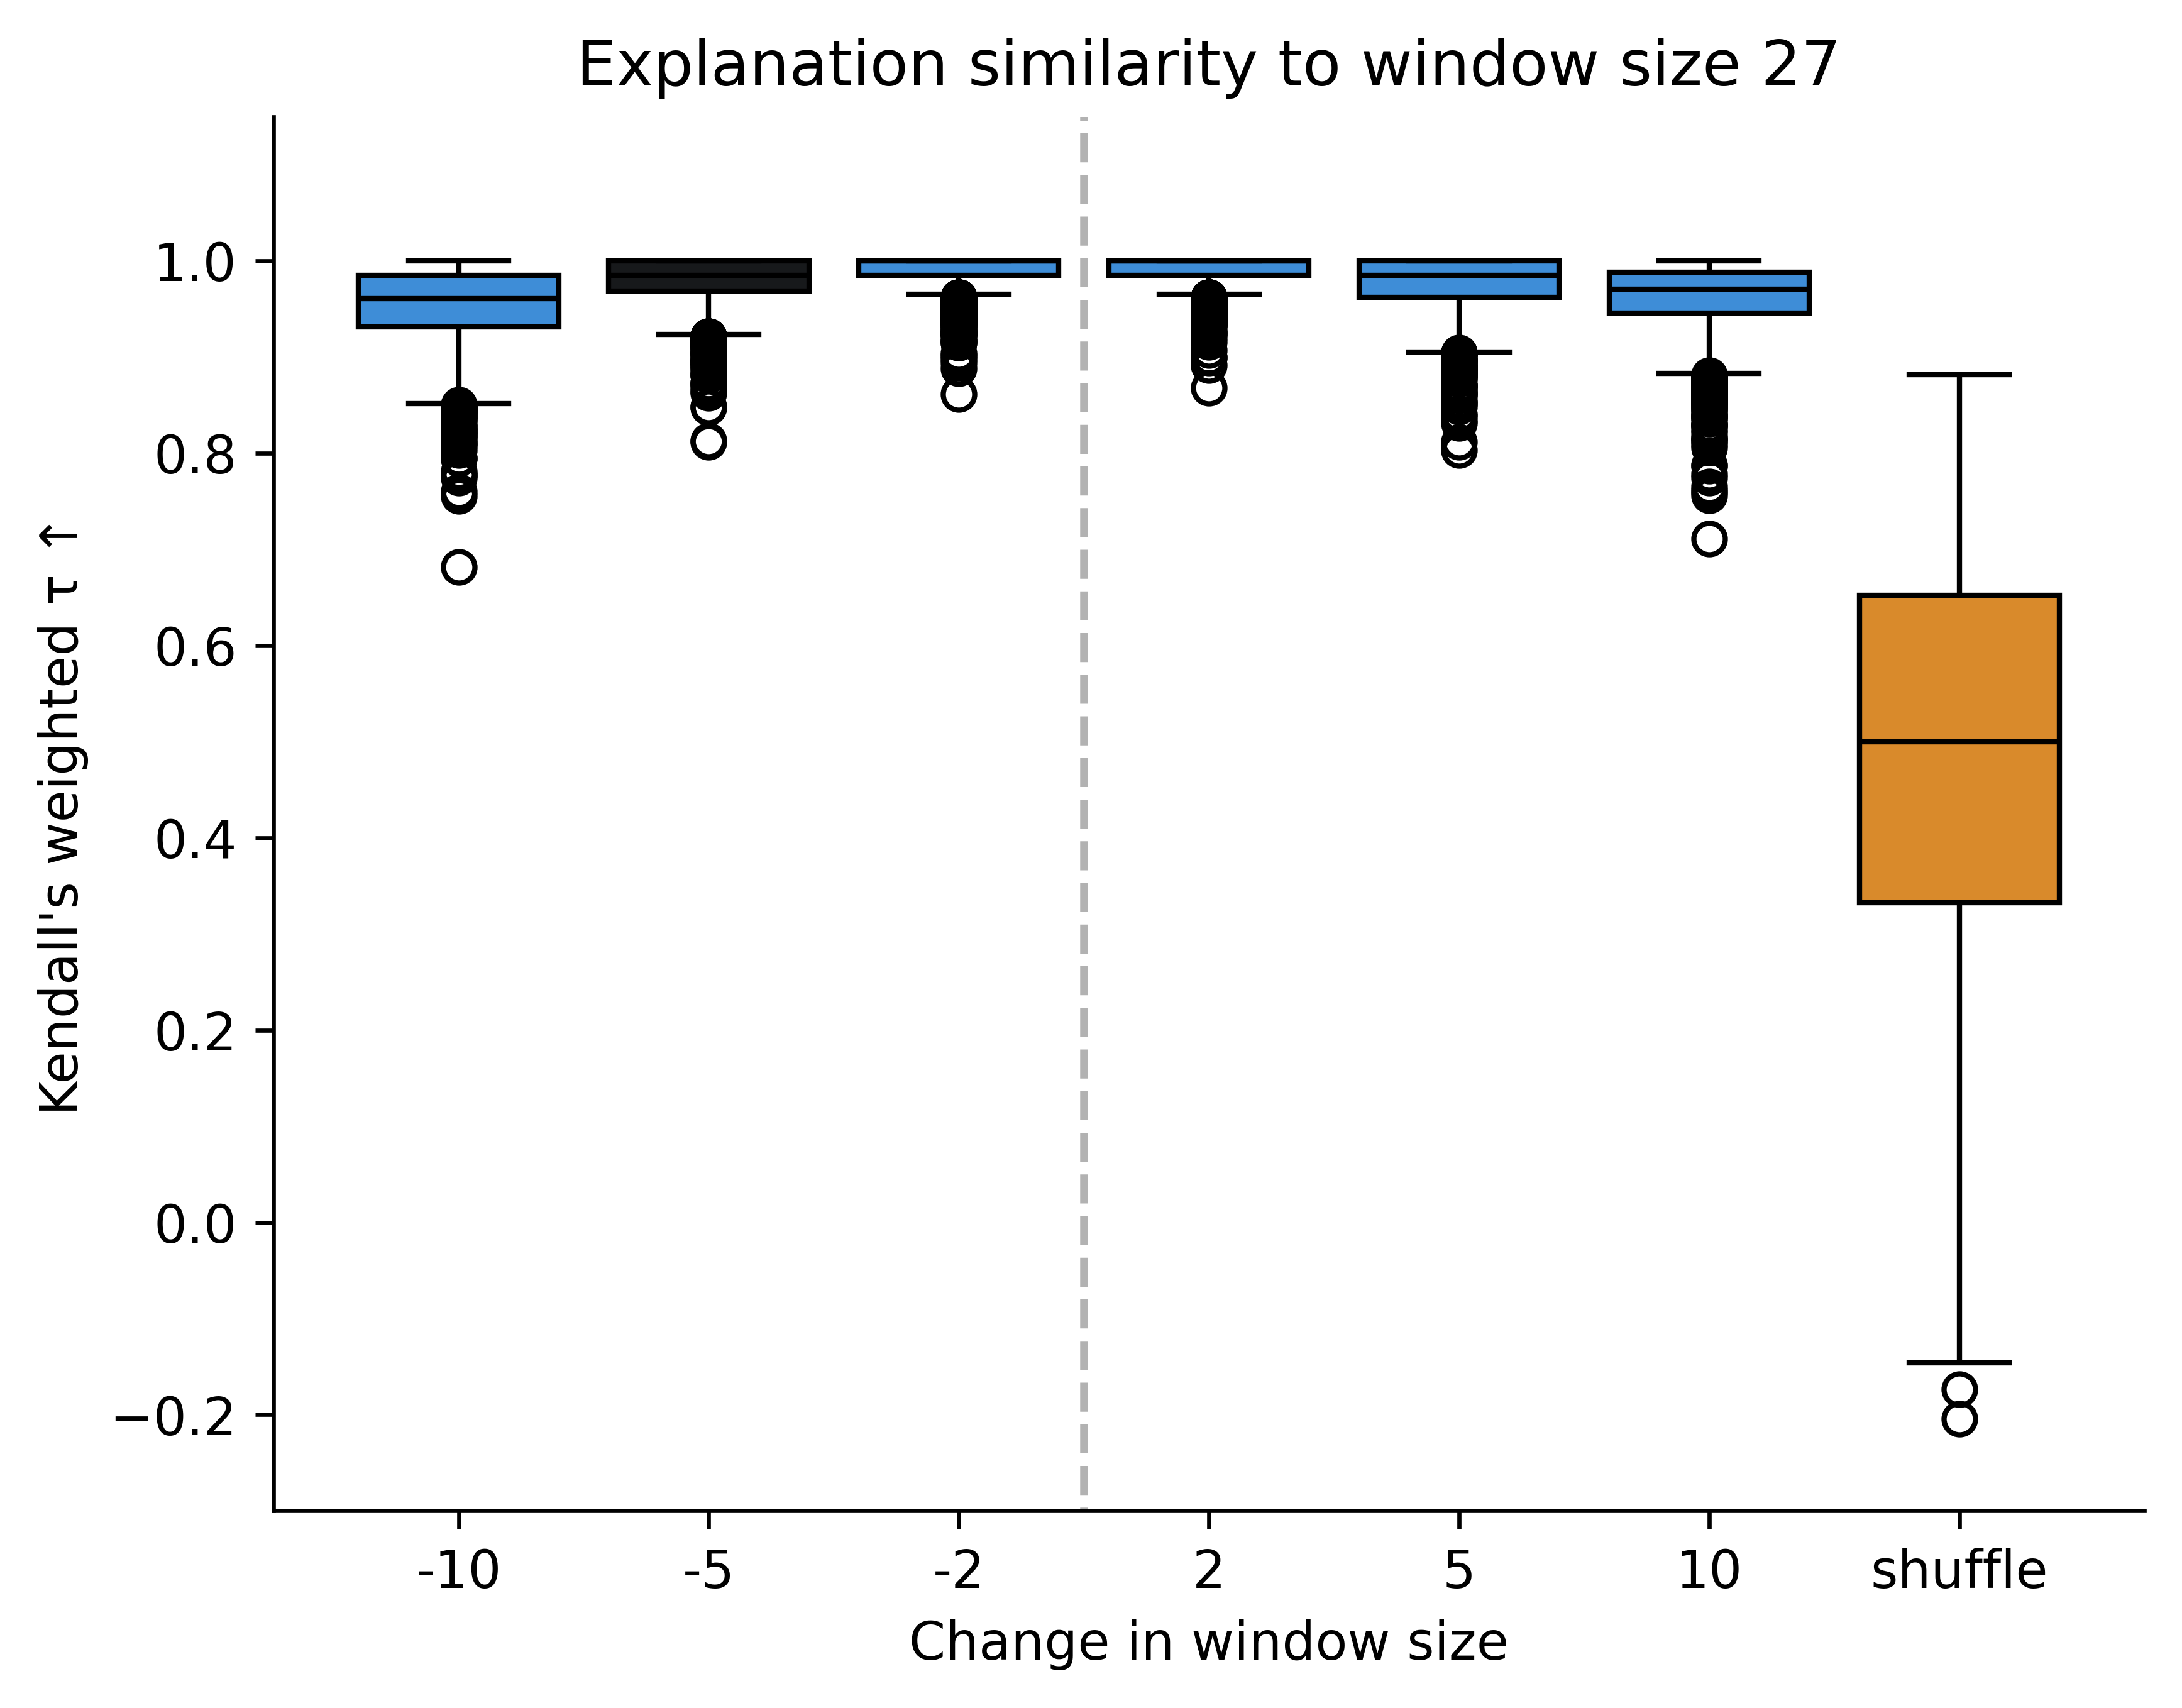

In [10]:
fig, ax = plt.subplots(dpi=600)

df_res = pd.DataFrame(mean_dict['opportunity_uni']['taus'])
colors = ['#248EF1', "#17191B", '#248EF1', '#248EF1', '#248EF1', '#248EF1', '#F68D0E']
my_pal = {v: c for v, c in zip(mean_dict['opportunity_uni']['taus'].keys(), colors)}
sb.boxplot(df_res, palette=my_pal, linecolor='k')
plt.xlabel('Change in window size')

# Annotate figure
ax.set_title('Explanation similarity to window size 27')
ax.set_ylabel('Kendall\'s weighted τ ↑')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

plt.ylim(-0.3, 1.15)

ax.vlines(2.5, -0.5, 1.5, colors='k', alpha=0.3, linestyles='--')

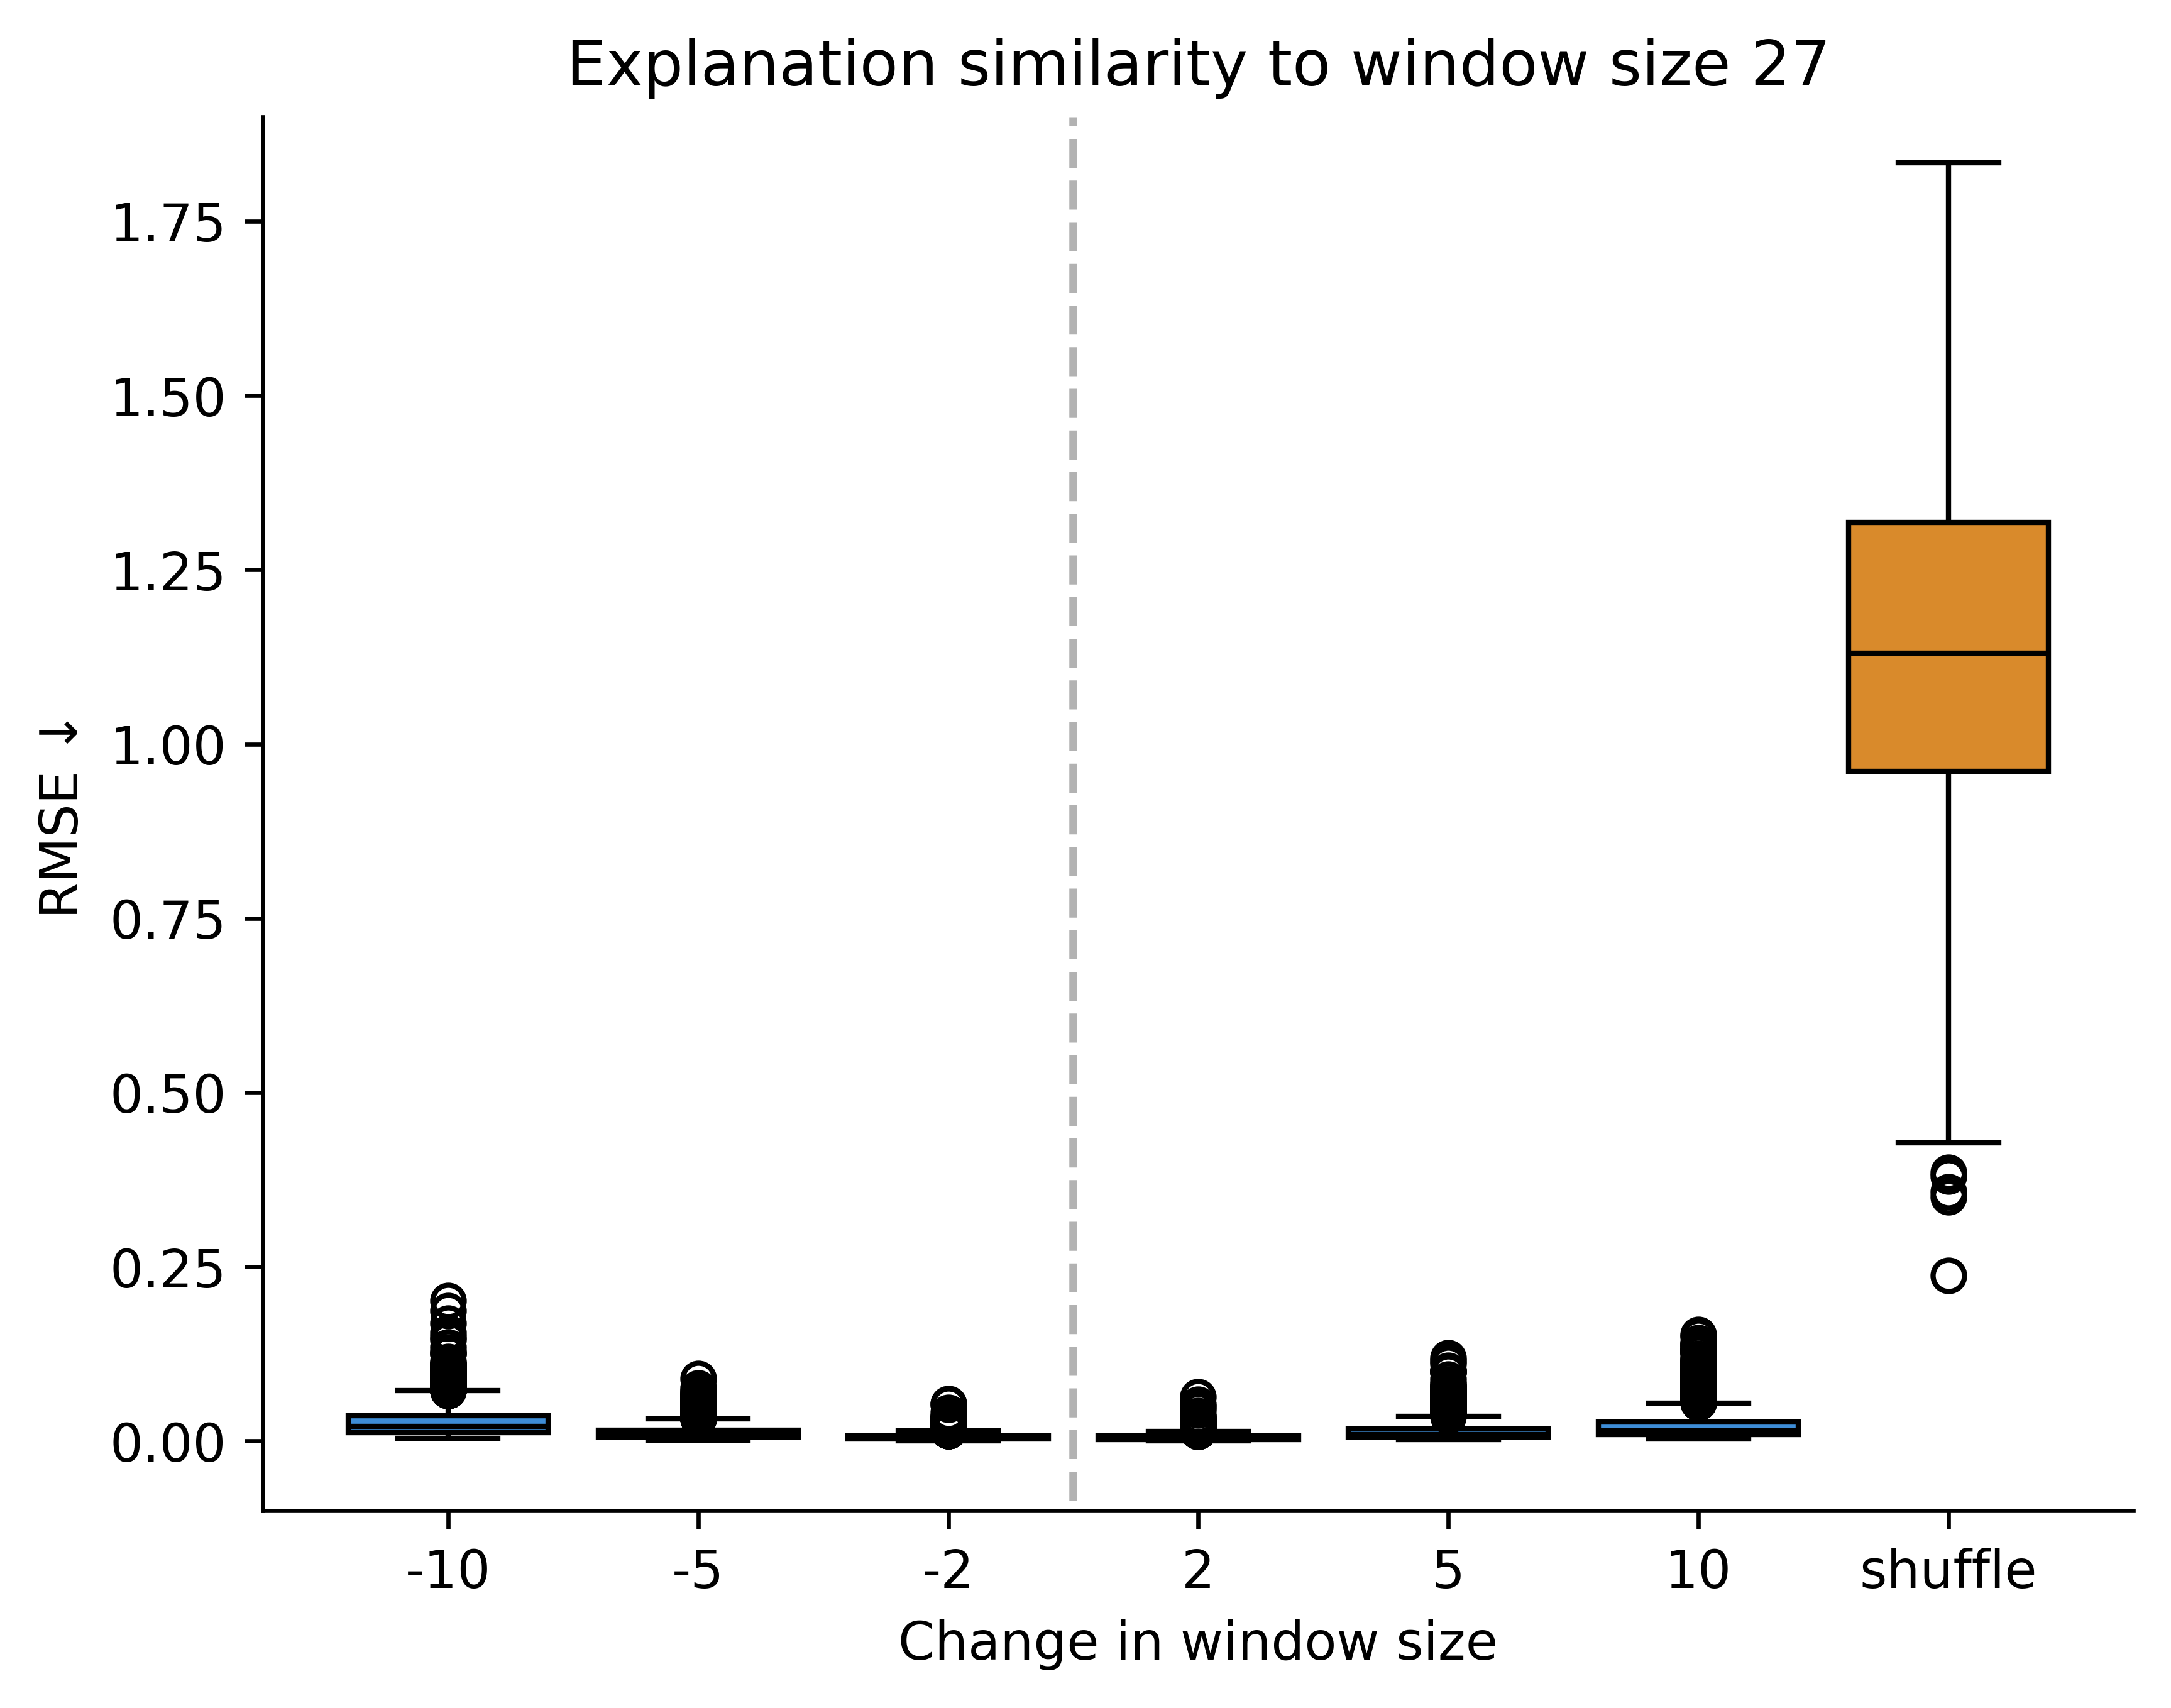

In [11]:
fig, ax = plt.subplots(dpi=600)

df_res = pd.DataFrame(mean_dict['opportunity_uni']['rmse'])
colors = ['#248EF1', '#248EF1', '#248EF1', '#248EF1', '#248EF1', '#248EF1', '#F68D0E']
my_pal = {v: c for v, c in zip(mean_dict['opportunity_uni']['rmse'].keys(), colors)}
sb.boxplot(df_res, palette=my_pal, linecolor='k')
plt.xlabel('Change in window size')

# Annotate figure
ax.set_title('Explanation similarity to window size 27')
ax.set_ylabel('RMSE ↓')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

plt.ylim(-0.1, 1.9)

ax.vlines(2.5, -0.5, 1.9, colors='k', alpha=0.3, linestyles='--')


In [12]:
result_dict = {d: {m: {}
               for m in ['taus', 'rmse']} for d in datasets}

In [13]:
for dataset in datasets:
    if dataset == 'opportunity_uni':
        og_value = 27
        task = 'classification'
        var_window_size = 27
        decomposition_def = 'trend+bias+scalex(low_freq+varxhigh_freq)'
    elif dataset == 'fordA':
        og_value = 50
        vals = [40, 45, 48, 52, 55, 60, 'shuffle']
        var_window_size = 50
        task = 'classification'
        decomposition_def = 'scalex(low_freq+varxhigh_freq)'
    elif dataset == 'turbofan':
        og_value = 30
        vals = [20, 25, 28, 32, 35, 40, 'shuffle']
        var_window_size = 30
        task = 'regression'
        decomposition_def = 'trend+bias+scalex(low_freq+varxhigh_freq)'
    vals = [0.25, 0.5, 0.75, 0.9, 1.25, 1.5, 'shuffle']

    result_dict[dataset]['taus'] = {v: [[]] * n_reps for v in vals} 
    result_dict[dataset]['rmse'] = {v: [[]] * n_reps for v in vals} 
    
    # Determine paths
    shap_path_og = './../data/cshap/' + dataset + '/uni_channel/' + decomposition_def
    shap_path_sa = './../data/results/sensitivity_analysis/' + dataset + '/uni_channel/' + decomposition_def
    model_path = './../models/' + dataset + '/uni_channel'

    for i in range(n_reps):
        for v in vals[:-1]:          # Iterate through the 5 pairs
        
            # Load paths based on selected models
            shap_path1 = shap_path_og + '/shap_values' + str(i) + '.pkl'
            shap_path2 = shap_path_sa +'/v_w_size_' + str(var_window_size) + '_noise_' + str(v) + '_shap_values_' + str(i) + '.pkl'

            base_path1 = shap_path_og + '/base_values' + str(i) + '.pkl'
            base_path2 = shap_path_sa + '/v_w_size_' + str(var_window_size) + '_noise_' + str(v) + '_base_values_' + str(i) + '.pkl'
            
            # Do pairwise sample comparisons
            weightedtaus, rmse = compare(shap_path1, shap_path2, base_path1, base_path2, task)

            # Store results
            result_dict[dataset]['taus'][v][i] = weightedtaus
            result_dict[dataset]['rmse'][v][i] = rmse

        # Do pairwise sample comparisons
        weightedtaus, rmse = compare_randomized(shap_path1, base_path1, task)

        # Store results
        result_dict[dataset]['taus']['shuffle'][i] = weightedtaus
        result_dict[dataset]['rmse']['shuffle'][i] = rmse

In [14]:
# Calculate means over shap pairs
mean_dict = {dataset: {t: {d: np.mean(sub_d, axis=0) 
                        for d, sub_d in sub_t.items()} 
                        for t, sub_t in sub.items()} for dataset, sub in result_dict.items()}

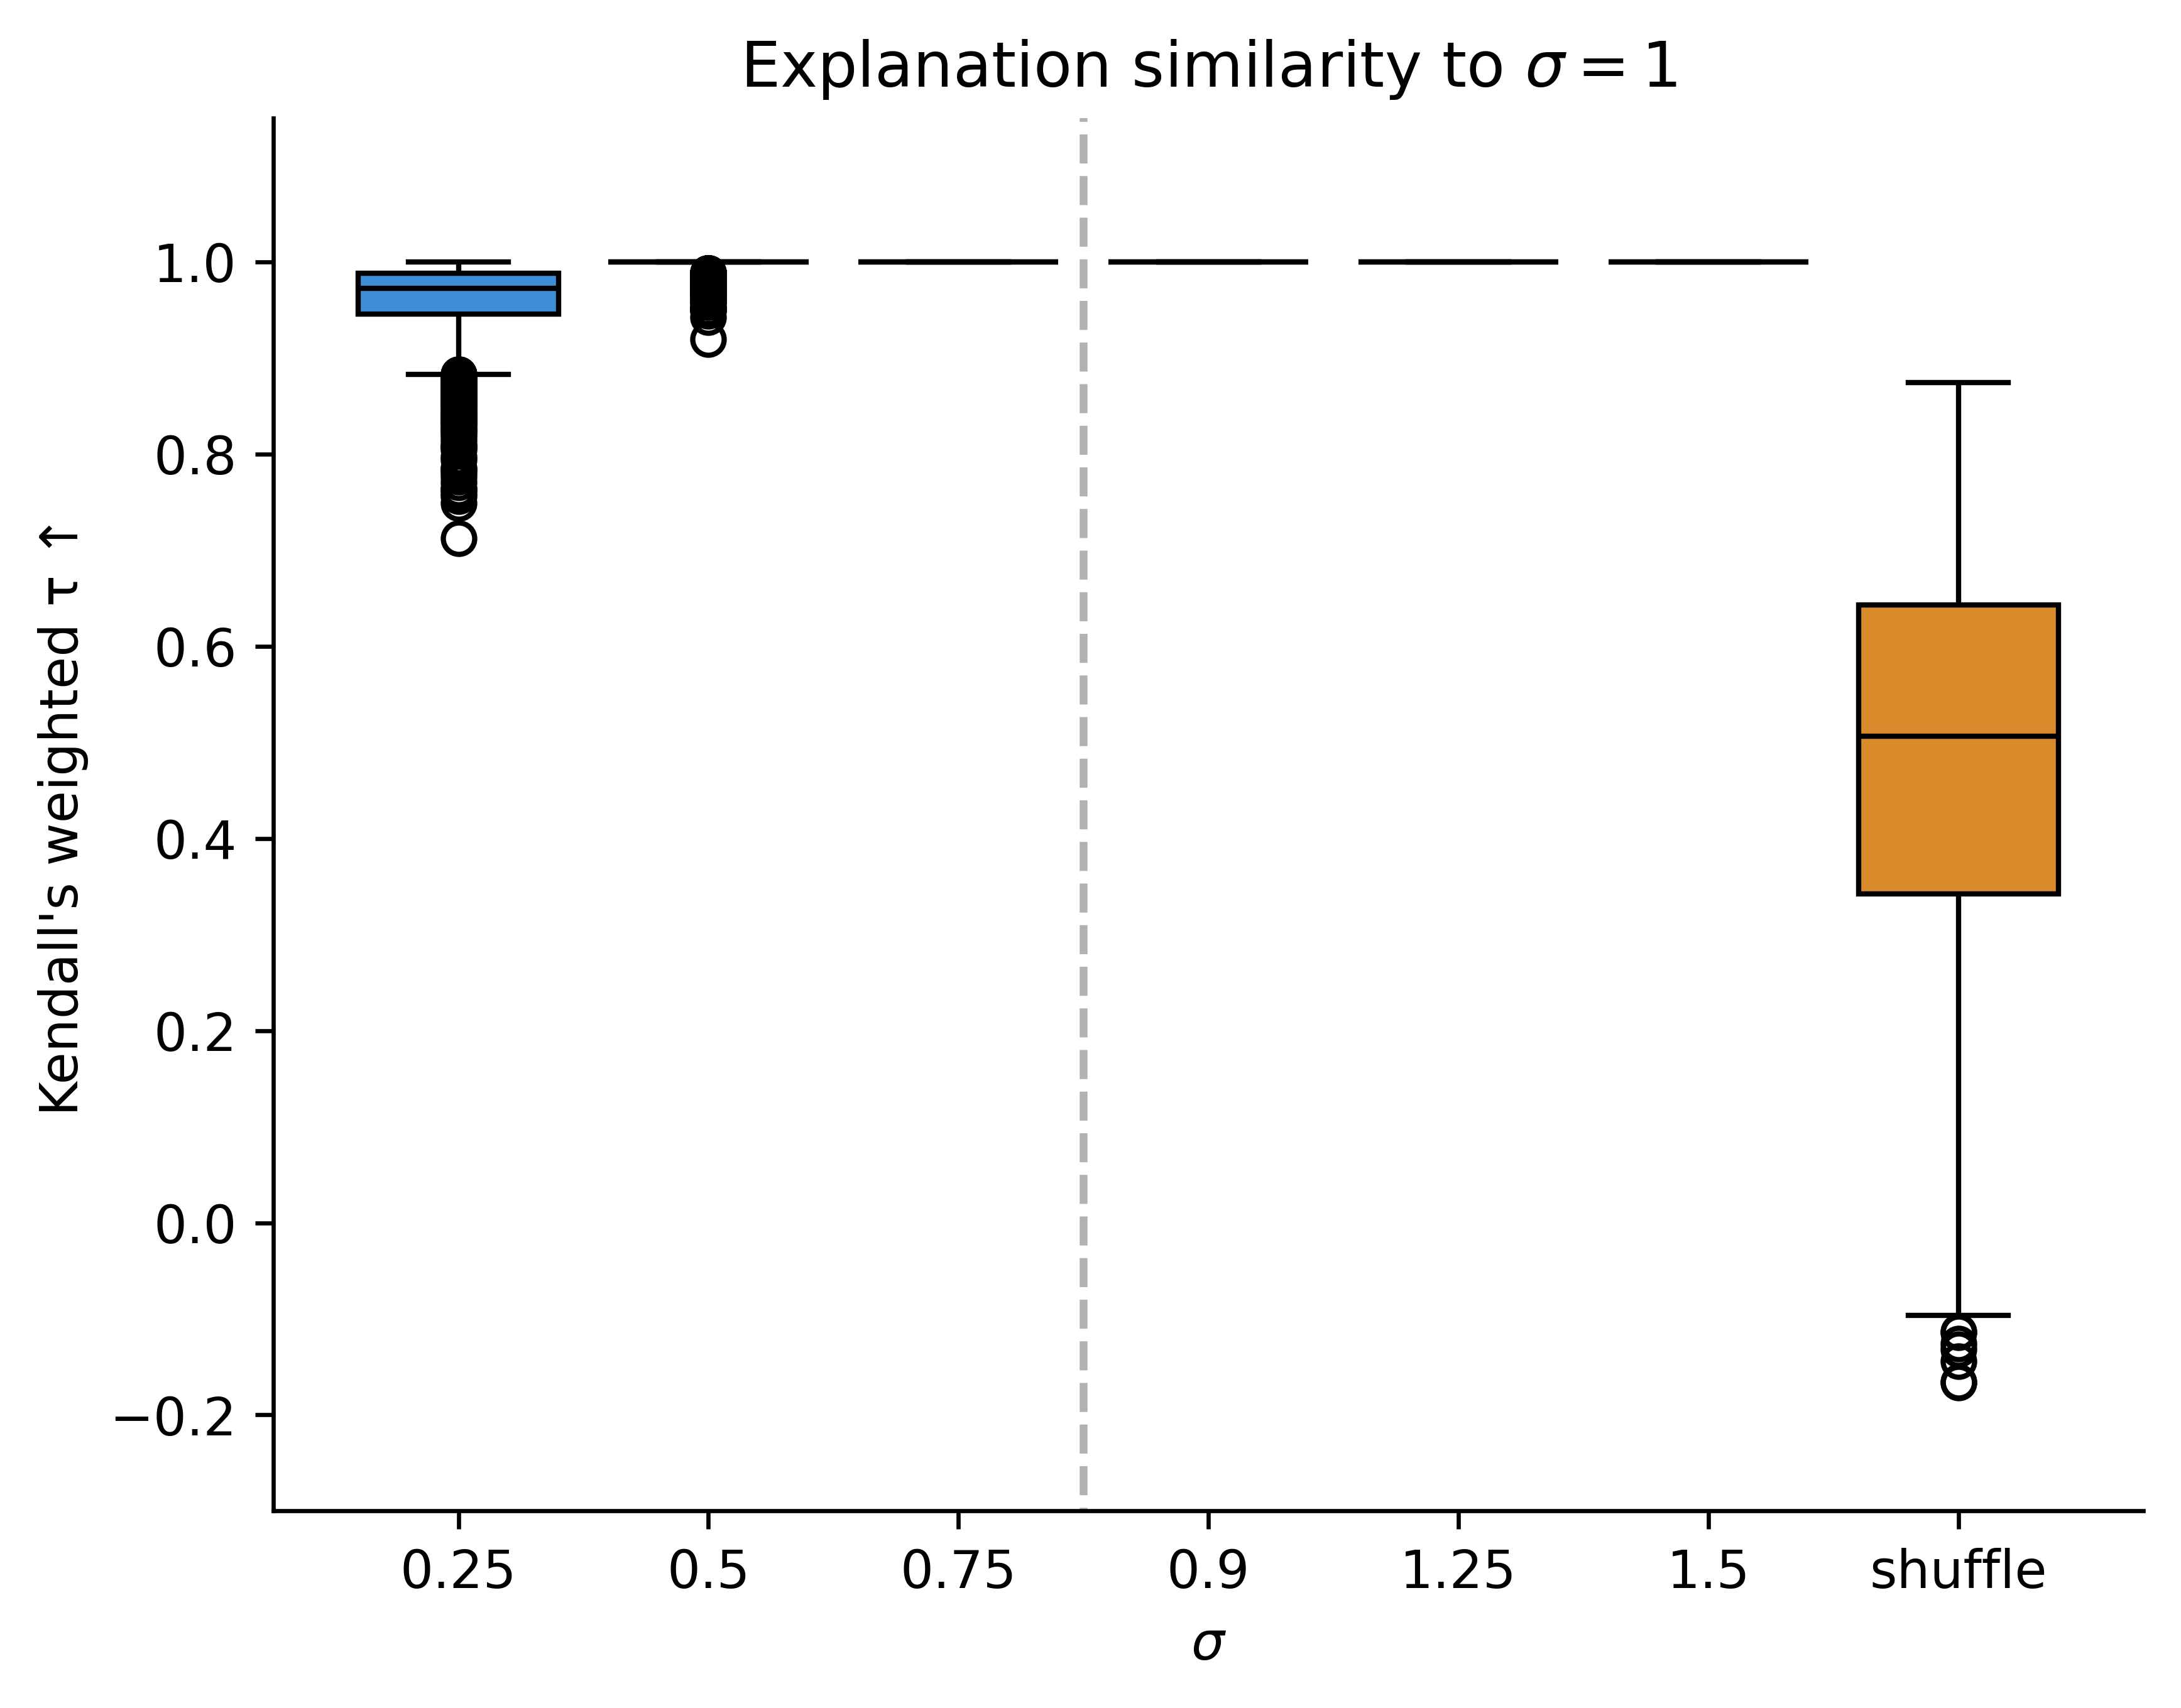

In [15]:
fig, ax = plt.subplots(dpi=600)

df_res = pd.DataFrame(mean_dict['opportunity_uni']['taus'])
colors = ['#248EF1', "#17191B", '#248EF1', '#248EF1', '#248EF1', '#248EF1', '#F68D0E']
my_pal = {v: c for v, c in zip(mean_dict['opportunity_uni']['taus'].keys(), colors)}
sb.boxplot(df_res, palette=my_pal, linecolor='k')
plt.xlabel('$\sigma$')

# Annotate figure
ax.set_title('Explanation similarity to $\sigma = 1$')
ax.set_ylabel('Kendall\'s weighted τ ↑')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

plt.ylim(-0.3, 1.15)

ax.vlines(2.5, -0.5, 1.5, colors='k', alpha=0.3, linestyles='--')

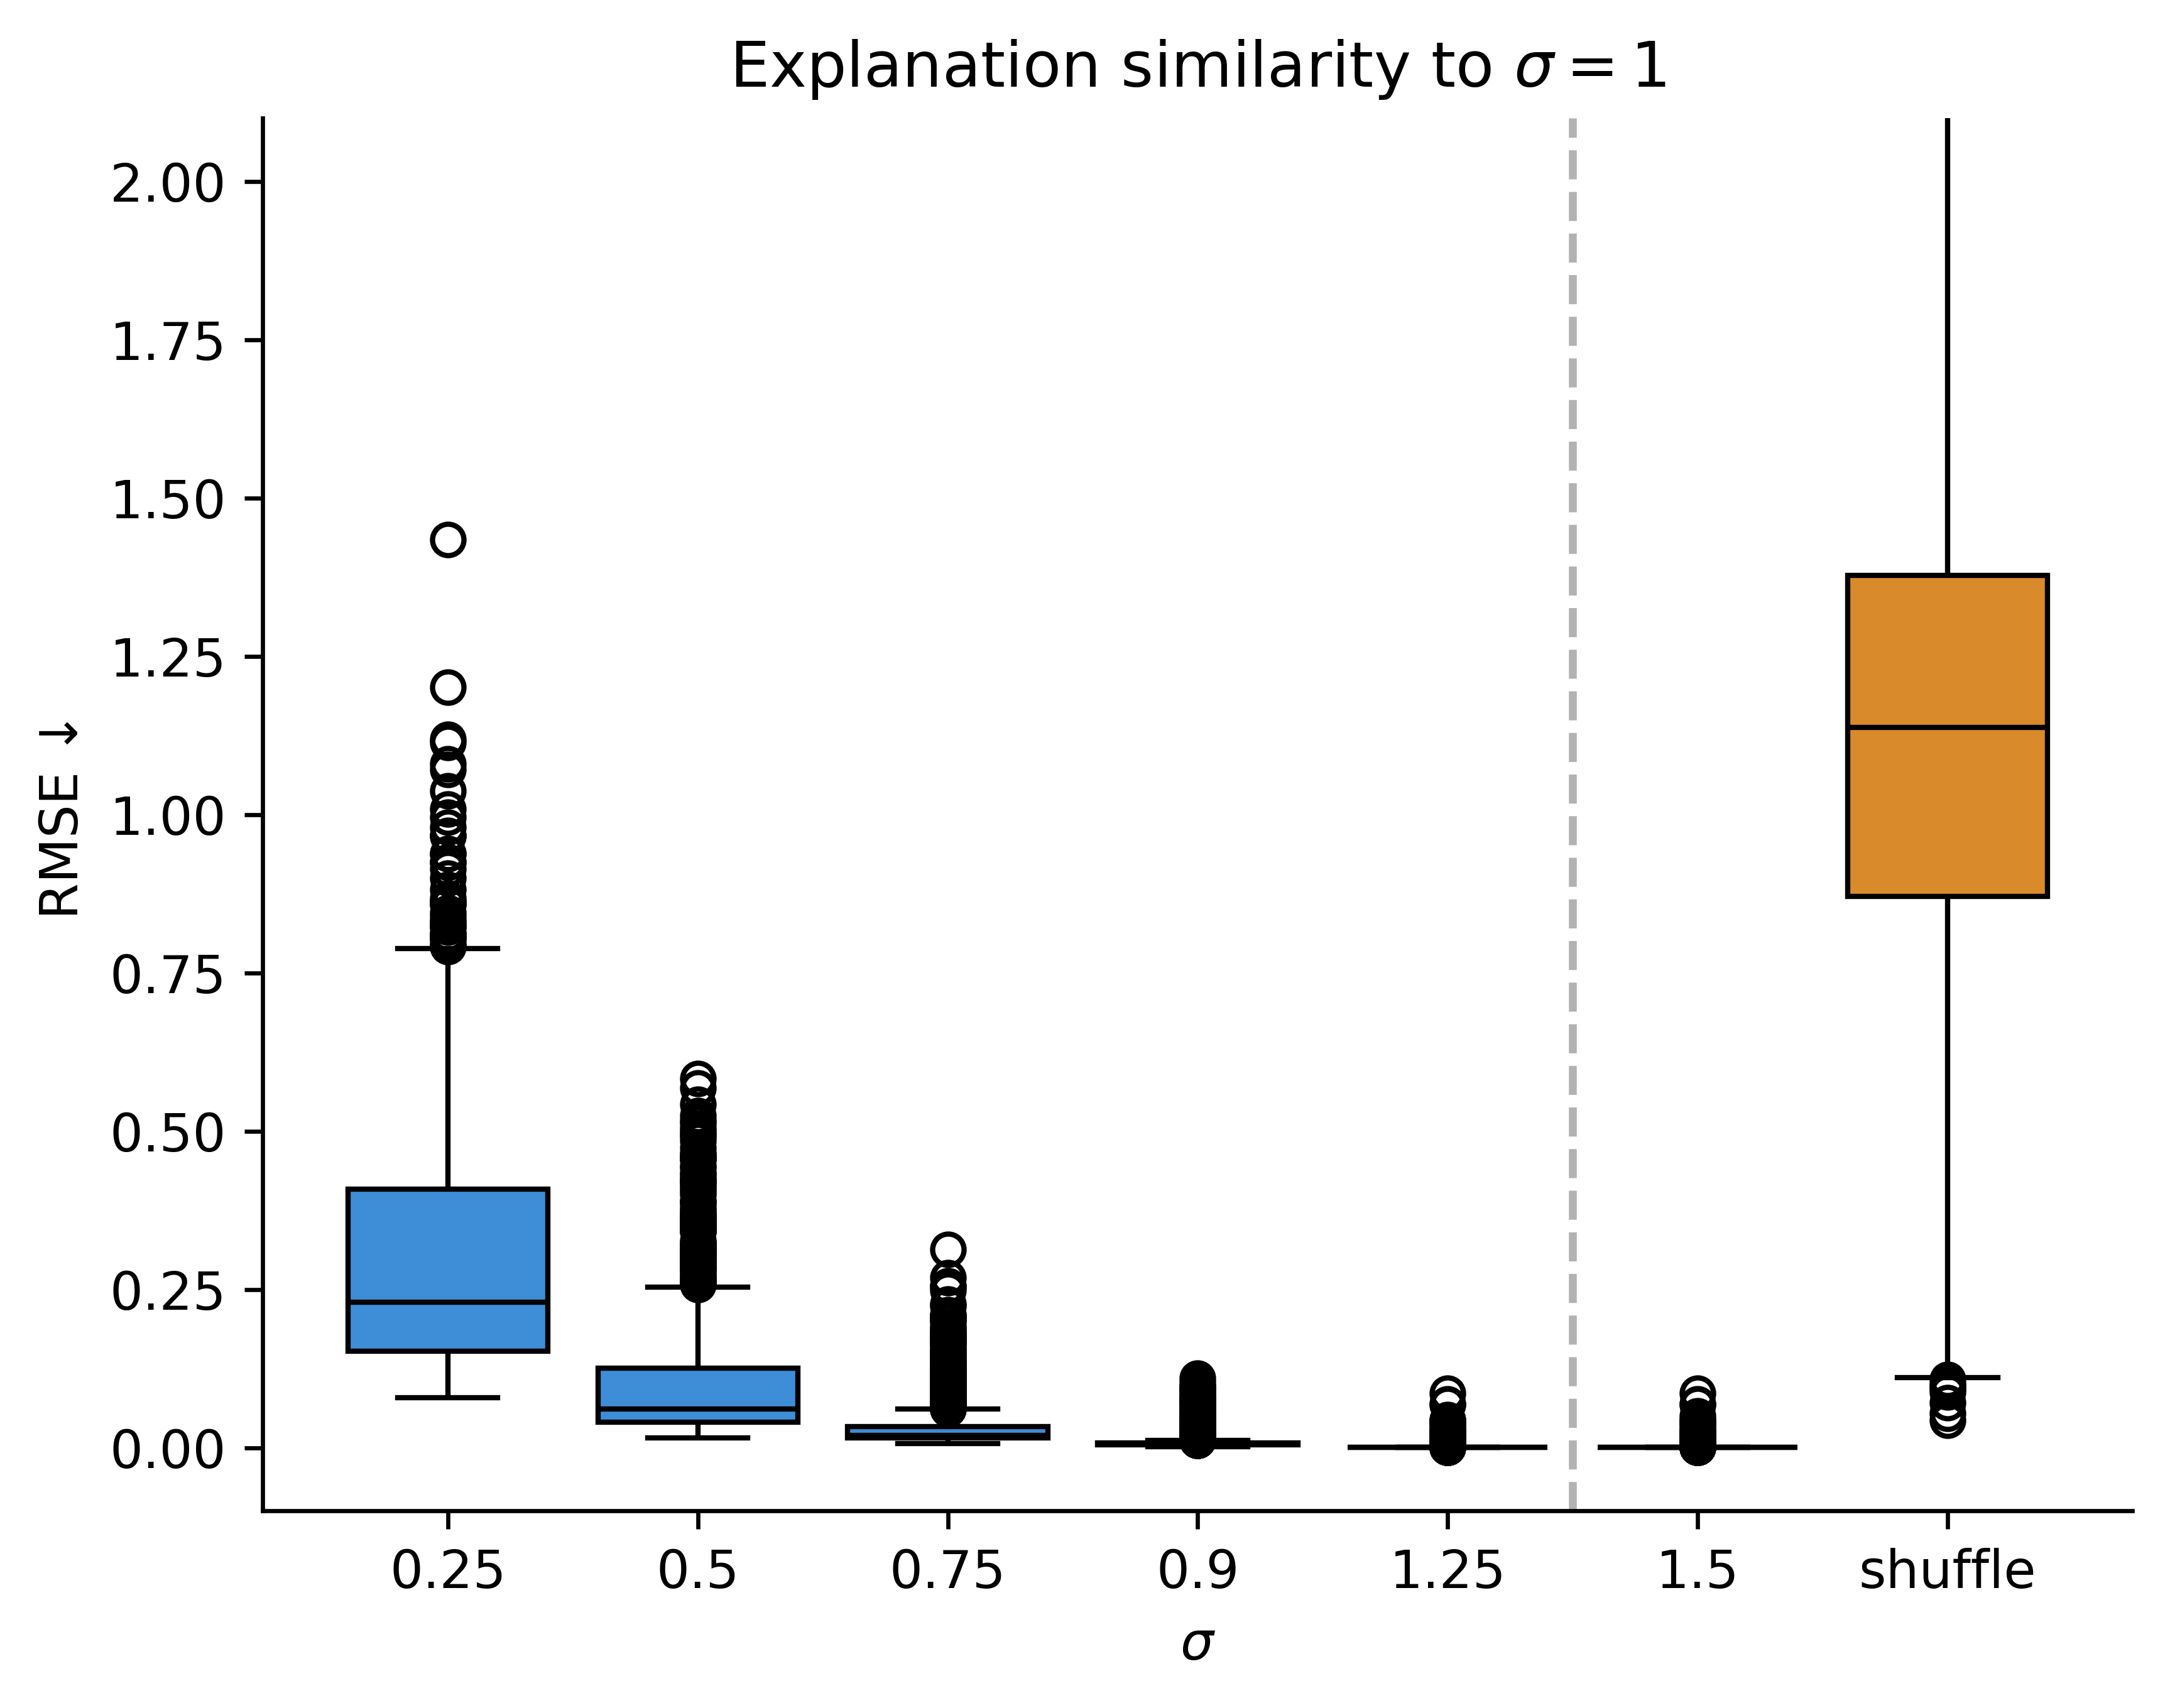

In [16]:

import pandas as pd
import seaborn as sb

fig, ax = plt.subplots(dpi=600)

df_res = pd.DataFrame(mean_dict['fordA']['rmse'])
colors = ['#248EF1', '#248EF1', '#248EF1', '#248EF1', '#248EF1', '#248EF1', '#F68D0E']
my_pal = {v: c for v, c in zip(vals, colors)}
sb.boxplot(df_res, palette=my_pal, linecolor='k')
plt.xlabel('$\sigma$')

# Annotate figure
ax.set_title('Explanation similarity to $\sigma = 1$')
ax.set_ylabel('RMSE ↓')

plt.ylim(-0.1, 2.1)

ax.vlines(4.5, -0.1, 2.1, colors='k', alpha=0.3, linestyles='--')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)